# QUiNN Tutorial: Uncertainty Quantification Methods

This notebook walks through all seven UQ-for-NN methods available in QUiNN.

**Methods covered:**

| Method | Class | Description |
|--------|-------|-------------|
| `amcmc` | `NN_MCMC` | Adaptive Metropolis MCMC |
| `hmc`   | `NN_MCMC` | Hamiltonian Monte Carlo |
| `vi`    | `NN_VI`   | Variational Inference (Bayes-by-Backprop) |
| `ens`   | `NN_Ens`  | Deep Ensemble |
| `rms`   | `NN_RMS`  | Randomized MAP Sampling |
| `laplace` | `NN_Laplace` | Laplace Approximation |
| `swag`  | `NN_SWAG` | Stochastic Weight Averaging Gaussian |

All methods share the same problem: fitting a 1-D function `true_model`,
observed with a small amount of noise.  The true model is set once in the
setup cell below and everything downstream refers to it generically, so a
single edit there switches the whole notebook to a different test function.
The underlying network is an `RNet` with polynomial weight parametrization.

Every plot is saved to **`figures/`** alongside this notebook.

## 1. Imports and global configuration

In [79]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from quinn.solvers.nn_vi      import NN_VI
from quinn.solvers.nn_ens     import NN_Ens
from quinn.solvers.nn_rms     import NN_RMS
from quinn.solvers.nn_mcmc    import NN_MCMC
from quinn.solvers.nn_swag    import NN_SWAG
from quinn.solvers.nn_laplace import NN_Laplace

from quinn.nns.rnet       import RNet, Poly
from quinn.utils.plotting import myrc, plot_vars
from quinn.utils.maps     import scale01ToDom
from quinn.func.funcs     import blundell, Sine, Summation, x5

torch.set_default_dtype(torch.double)
myrc()  # QUiNN's default matplotlib style

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# output directory for all saved figures
FIGDIR = 'figures'
os.makedirs(FIGDIR, exist_ok=True)
print(f'Figures will be saved to: {os.path.abspath(FIGDIR)}/')

Using device: cpu
Figures will be saved to: /Users/ksargsy/Dropbox/Work/repos/quinn/examples/figures/


## 2. Problem setup

The function to be learned is set once, as `true_model`, and referred to
generically everywhere below.  The default is `blundell`, the classic
example of Blundell et al. (2015),

$$y = x + 0.3\sin\big(2\pi(x+\epsilon)\big) + 0.3\sin\big(4\pi(x+\epsilon)\big) + \epsilon,
\qquad \epsilon \sim \sigma\,\mathcal{N}(0,1), \qquad x \in [0, 1]$$

Note that for this particular function the noise $\epsilon$ enters both the
input and the output.  Calling it with `datanoise=0` gives the noise-free
ground truth.

**Where the data live.**  Training and validation points are drawn only from
two windows, $[0.2, 0.4]$ and $[0.6, 0.8]$ of the domain.  The gaps between
and outside them are where a UQ method has to extrapolate, and therefore where
it ought to report *large* uncertainty — which is what makes the seven methods
worth telling apart.  Test points are spread over the whole domain, so the
test metrics see both the interpolation and the extrapolation regime.

To swap in a different test function, change `true_model` and `domain`
together in the cell below — the rest of the notebook follows along.  Other
single-output 1-D choices in `quinn.func.funcs` are `Sine` (on $[-\pi,\pi]$),
`Summation` and `x5` (both on $[-1,1]$).

True model: blundell on [0, 1]
Train/val windows: [0.2, 0.4], [0.6, 0.8]
Training: (30, 1)  Validation: (10, 1)  Testing: (60, 1)


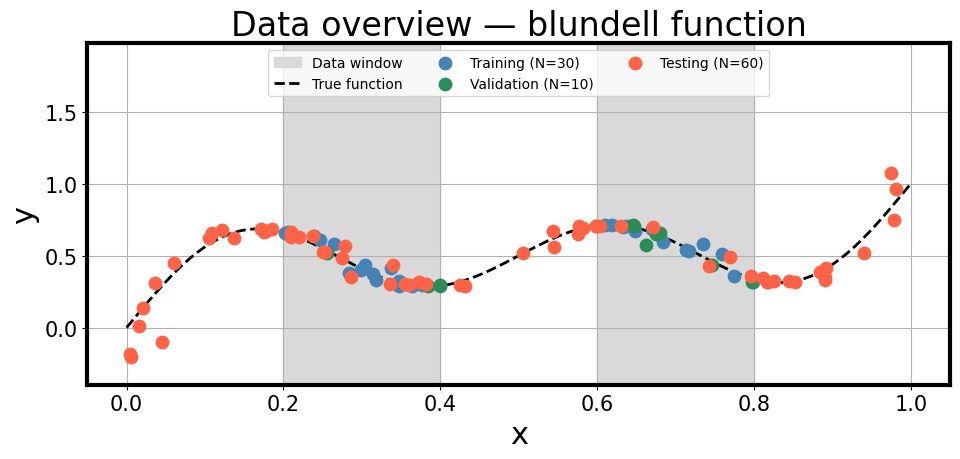

Saved: data_overview.png


In [80]:
#np.random.seed(42)

# ── the function being learned, and the domain it lives on ───────────────────
# These two go together: change both to switch to a different test function.
true_model = blundell
domain     = np.tile(np.array([0.0, 1.0]), (1, 1))  # (ndim, 2)

ndim       = 1
nout       = 1
datanoise  = 0.02
trn_factor = 0.75

# Training and validation points are confined to these windows, given as
# fractions of the domain. Everything outside is an extrapolation region.
windows01 = [(0.2, 0.4), (0.6, 0.8)]
WINDOWS = [tuple(scale01ToDom(np.array([[lo], [hi]]), domain)[:, 0])
           for lo, hi in windows01]

# training + validation, drawn from the windows only
nall    = 40
per_win = nall // len(windows01)
xall01  = np.vstack([lo + (hi - lo) * np.random.rand(per_win, ndim)
                     for lo, hi in windows01])
np.random.shuffle(xall01)   # so the train/val split is not one window each
xall = scale01ToDom(xall01, domain)
yall = true_model(xall, datanoise=datanoise)

ntrn = int(trn_factor * nall)
xtrn, xval = xall[:ntrn], xall[ntrn:]
ytrn, yval = yall[:ntrn], yall[ntrn:]

# test set, over the whole domain (fixed seed)
np.random.seed(100)
ntst = 60
xtst = scale01ToDom(np.random.rand(ntst, ndim), domain)
ytst = true_model(xtst, datanoise=datanoise)

# dense evaluation grid
xgrid = scale01ToDom(np.linspace(0.0, 1.0, 111)[:, np.newaxis], domain)
ytrue = true_model(xgrid, datanoise=0.0)  # noise-free ground truth

xx_list = [xtrn, xval, xtst]
yy_list = [ytrn, yval, ytst]
ll_list = ['Training', 'Validation', 'Testing']

# ── shared y-range for every fit plot ────────────────────────────────────────
# The generous headroom at the top is what keeps the 3-column legend clear of
# the curves; a common range across methods keeps the plots comparable.
_ref = np.concatenate([ytrue[:, 0], ytrn[:, 0], yval[:, 0], ytst[:, 0]])
_lo, _hi = _ref.min(), _ref.max()
YLIM = (_lo - 0.15 * (_hi - _lo), _hi + 0.70 * (_hi - _lo))


def shade_windows(ax):
    """Shade the windows the training data was drawn from."""
    for i, (lo, hi) in enumerate(WINDOWS):
        ax.axvspan(lo, hi, color='0.85', zorder=-10,
                   label='Data window' if i == 0 else None)


print(f'True model: {true_model.__name__} on '
      f'[{domain[0, 0]:.3g}, {domain[0, 1]:.3g}]')
print('Train/val windows: ' +
      ', '.join(f'[{lo:.3g}, {hi:.3g}]' for lo, hi in WINDOWS))
print(f'Training: {xtrn.shape}  Validation: {xval.shape}  Testing: {xtst.shape}')

# ── data overview figure ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
shade_windows(ax)
ax.plot(xgrid[:, 0], ytrue[:, 0], 'k--', lw=2, label='True function')
ax.scatter(xtrn[:, 0], ytrn[:, 0], c='steelblue', s=80, zorder=5, label=f'Training (N={len(xtrn)})')
ax.scatter(xval[:, 0], yval[:, 0], c='seagreen',  s=80, zorder=5, label=f'Validation (N={len(xval)})')
ax.scatter(xtst[:, 0], ytst[:, 0], c='tomato',    s=80, zorder=5, label=f'Testing (N={len(xtst)})')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_ylim(*YLIM)
ax.set_title(f'Data overview — {true_model.__name__} function')
ax.legend(loc='upper center', ncol=3, fontsize=10, framealpha=0.8)
plt.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'data_overview.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: data_overview.png')

## 3. Shared utilities

### 3.1 Network factory

Each UQ method needs its own fresh copy of the network (weights must not
be shared across experiments).  The factory constructs an `RNet` — a
residual network whose layer weights are parametrized by `Poly(order)`
basis functions.

In [81]:
def make_nnet(seed=1):
    """Return a freshly initialized RNet with polynomial weight parametrization.

    The seed is reset here so that every method below starts from the same
    network and sees the same stream of random numbers afterwards (data
    subsets, MCMC proposals, ...).  Without it the methods are not comparable
    and, for the sampling methods in particular, results vary noticeably from
    run to run.
    """
    np.random.seed(seed)
    torch.manual_seed(seed)
    return RNet(
        3, 3,
        wp_function=Poly(0),
        indim=ndim, outdim=nout,
        layer_pre=True, layer_post=True,
        biasorno=True, nonlin=True,
        mlp=False, final_layer=None,
        device=device,
    )

### 3.2 Visualisation helper

`show_fit` calls `predict_mom_sample` (draws `nsam` posterior samples and
computes mean + variance) and renders an inline plot showing:
- predictive mean and ±1 std band (via `plot_vars`),
- noise-free ground truth,
- training / validation / test scatter.

The figure is saved to `figures/fit_<slug>.png`.

In [82]:
def show_fit(uqnet, title, slug, nsam=200):
    """1-D uncertainty plot; saves to figures/fit_<slug>.png."""
    ymean, yvar, _ = uqnet.predict_mom_sample(xgrid, msc=1, nsam=nsam)
    ystd = np.sqrt(yvar[:, 0])

    BAND_COLOR = '#9970ab'   # medium purple — fill
    LINE_COLOR = '#40004b'   # deep purple  — mean line

    fig, ax = plt.subplots(figsize=(10, 5))
    shade_windows(ax)

    # z=1  band (lighter shade)
    ax.fill_between(xgrid[:, 0],
                    ymean[:, 0] - ystd,
                    ymean[:, 0] + ystd,
                    color=BAND_COLOR, alpha=0.35,
                    label='±1 Std. dev.', zorder=1)
    # z=2  mean prediction (darker shade of same hue)
    ax.plot(xgrid[:, 0], ymean[:, 0],
            color=LINE_COLOR, lw=2.5,
            label='Mean prediction', zorder=2)
    # z=3  true function
    ax.plot(xgrid[:, 0], ytrue[:, 0],
            'k--', lw=2, alpha=0.6,
            label='True function', zorder=3)
    # z=4  data points
    ax.scatter(xtrn[:, 0], ytrn[:, 0],
               c='#2166ac', s=110, zorder=4,
               edgecolors='white', linewidths=1.2,
               label=f'Training (N={len(xtrn)})')
    ax.scatter(xval[:, 0], yval[:, 0],
               c='#1a9641', s=110, zorder=4,
               edgecolors='white', linewidths=1.2,
               label=f'Validation (N={len(xval)})')
    ax.scatter(xtst[:, 0], ytst[:, 0],
               c='#d7191c', s=110, zorder=4,
               edgecolors='white', linewidths=1.2,
               label=f'Testing (N={len(xtst)})')

    ax.set_xlabel('x'); ax.set_ylabel('y')
    # Common y-range across all methods, with headroom for the legend
    ax.set_ylim(*YLIM)
    ax.set_title(title, fontsize=14)
    ax.legend(loc='upper center', ncol=3, fontsize=10, framealpha=0.8)
    plt.tight_layout()

    fname = os.path.join(FIGDIR, f'fit_{slug}.png')
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: fit_{slug}.png')

### 3.3 Scoring helpers

Three complementary numbers are used in the comparison at the end.  They
answer different questions, and a method can do well on one and badly on
another:

| Quantity | Answers | Best |
|----------|---------|------|
| **RMSE** | Is the *mean* prediction accurate? | 0 |
| **AUC** — area between the UC curve and the diagonal | Is the *uncertainty* the right size? | 0 |
| **CRPS** — continuous ranked probability score | Is the *whole predictive distribution* good? | 0 |

The RMSE ignores the uncertainty entirely, so a badly overconfident method can
still score well on it.  The AUC ignores the mean, so a method can be perfectly
calibrated while predicting nonsense — a wide enough band is "calibrated" no
matter where it is centred.  CRPS is the one that penalises both at once, and
reduces to the mean absolute error when the predictive distribution collapses
to a point.

All three are scored against **noisy observations**, so the predictive
distribution has to include the observation noise, not just the spread over
network weights.  `predictive_samples` below adds it.

In [83]:
NMC_EVAL = 300   # predictive samples drawn per method for the metrics below


def predictive_samples(uqnet, x, nmc=NMC_EVAL, seed=0):
    """Draw predictive samples of the observable `y` at inputs `x`.

    The solvers return samples of the mean *function*, i.e. the epistemic
    spread over network weights only.  The data being scored are noisy, so the
    observation noise is added on top here; without it every method would look
    badly overconfident.  Methods whose `predict_ens` is capped at their
    ensemble size (`NN_Ens`, `NN_RMS`) are resampled with replacement, so that
    every method is scored with the same number of samples.

    Args:
        uqnet: A fitted QUiNN solver.
        x (np.ndarray): `(N,d)` input array.
        nmc (int, optional): Number of predictive samples.
        seed (int, optional): Seed for the resampling and the added noise.

    Returns:
        np.ndarray: `(nmc, N, o)` array of predictive samples.
    """
    rng = np.random.default_rng(seed)
    ens = uqnet.predict_ens(x, nens=nmc)             # (M,N,o), M may be < nmc
    ens = ens[rng.integers(0, ens.shape[0], size=nmc)]
    return ens + rng.normal(0.0, datanoise, size=ens.shape)


def rmse(samples, y):
    """Root mean square error of the predictive mean: quality of the mean fit.

    Args:
        samples (np.ndarray): `(M,N,o)` predictive samples.
        y (np.ndarray): `(N,o)` observed outputs.

    Returns:
        float: The RMSE.
    """
    return float(np.sqrt(np.mean((samples.mean(axis=0) - y)**2)))


def uc_curve(samples, y, nlevels=101):
    r"""Uncertainty calibration (UC) curve.

    For each nominal probability level :math:`q`, this is the fraction of
    observations whose own predictive CDF value :math:`F(y)` is at most
    :math:`q`.  A perfectly calibrated predictive distribution lands on the
    diagonal: 30% of the observations should fall below the 30th percentile of
    their own predictive distribution.  A curve *below* the diagonal means the
    predictions are over-confident (bands too narrow), *above* means
    under-confident.

    Args:
        samples (np.ndarray): `(M,N,o)` predictive samples.
        y (np.ndarray): `(N,o)` observed outputs.
        nlevels (int, optional): Number of probability levels.

    Returns:
        tuple(np.ndarray, np.ndarray): Nominal levels and observed fractions.
    """
    levels = np.linspace(0.0, 1.0, nlevels)
    pit = np.mean(samples <= y[np.newaxis, ...], axis=0).ravel()   # F(y)
    observed = np.array([np.mean(pit <= q) for q in levels])

    return levels, observed


def calibration_auc(levels, observed):
    """Area between the UC curve and the diagonal: quality of the UQ.

    Zero is perfect calibration; the worst possible value is 0.5.

    Args:
        levels (np.ndarray): Nominal probability levels.
        observed (np.ndarray): Observed fractions, from :func:`uc_curve`.

    Returns:
        float: The area.
    """
    return float(np.trapezoid(np.abs(observed - levels), levels))


def crps(samples, y):
    r"""Continuous ranked probability score: quality of the whole prediction.

    Sample estimator of
    :math:`\textrm{CRPS} = E|X-y| - \frac{1}{2}E|X-X'|`, with :math:`X, X'`
    independent draws from the predictive distribution.  Lower is better.
    Unlike the RMSE it scores the full predictive distribution, so it rewards
    an honestly sized uncertainty as well as an accurate mean.

    Args:
        samples (np.ndarray): `(M,N,o)` predictive samples.
        y (np.ndarray): `(N,o)` observed outputs.

    Returns:
        float: CRPS averaged over the points.
    """
    ss = samples[:, :, 0]                                   # (M,N)
    obs = y[:, 0]                                           # (N,)
    spread = np.mean(np.abs(ss[:, np.newaxis, :] - ss[np.newaxis, :, :]),
                     axis=(0, 1))
    accuracy = np.mean(np.abs(ss - obs), axis=0)

    return float(np.mean(accuracy - 0.5 * spread))

---
## Method 1 — Adaptive Metropolis MCMC (`amcmc`)

**Idea:** treat all network weights as random variables and sample the
posterior $p(\theta \mid \mathcal{D})$ with the Adaptive Metropolis algorithm,
which adapts its proposal covariance on-the-fly.

**Key hyper-parameters:**
- `nmcmc` — total MCMC steps (burn-in included).
- `gamma` — initial proposal scale.
- `datanoise` — assumed observation noise standard deviation.

Uncertainty comes from the spread of the posterior weight samples.

In [84]:
nnet = make_nnet()
uqnet_amcmc = NN_MCMC(nnet, verbose=True)

# zflag=True starts the chain at the MAP (found by a preceding optimization).
# Without it, the chain spends its whole budget wandering in from a random
# starting point and the fit comes out flat.
sampler_params = {'gamma': 0.2}   # proposal scale; too small and the chain does not mix
uqnet_amcmc.fit(
    xtrn, ytrn,
    zflag=True,
    datanoise=datanoise,
    nmcmc=10000,
    sampler='amcmc',
    sampler_params=sampler_params,
)

Number of parameters: 22
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
1000 / 10000 completed, acceptance rate 0
2000 / 10000 completed, acceptance rate 0.496748
3000 / 10000 completed, acceptance rate 0.66022
4000 / 10000 completed, acceptance rate 0.735184
5000 / 10000 completed, acceptance rate 0.775355
6000 / 10000 completed, acceptance rate 0.7988
7000 / 10000 completed, acceptance rate 0.814974
8000 / 10000 completed, acceptance rate 0.821853
9000 / 10000 completed, acceptance rate 0.82787
10000 / 10000 completed, acceptance rate 0.831883


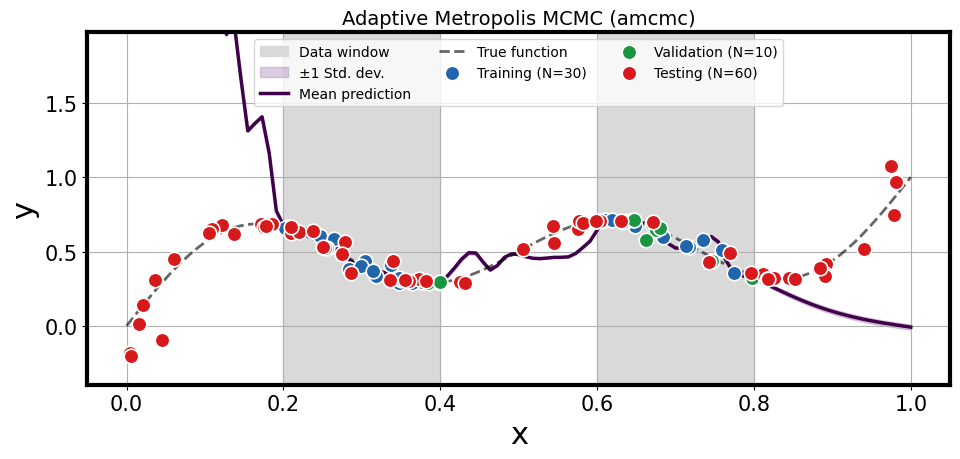

Saved: fit_amcmc.png


In [85]:
show_fit(uqnet_amcmc, 'Adaptive Metropolis MCMC (amcmc)', slug='amcmc')

---
## Method 2 — Hamiltonian Monte Carlo (`hmc`)

**Idea:** use gradient information to propose large moves in weight space,
dramatically reducing autocorrelation compared to random-walk MCMC.

**Key hyper-parameters:**
- `L` — number of leapfrog integration steps per proposal.
- `epsilon` — leapfrog step size.

In [86]:
nnet = make_nnet()
uqnet_hmc = NN_MCMC(nnet, verbose=True)

# epsilon is the leapfrog step size, and it matters a great deal: at the 2.5e-3
# used for easier targets the leapfrog integration diverges here and *every*
# proposal is rejected (acceptance rate 0, i.e. the chain never leaves its
# starting point). Watch the acceptance rate printed below when changing it.
sampler_params = {'L': 3, 'epsilon': 2.0e-5}
uqnet_hmc.fit(
    xtrn, ytrn,
    zflag=True,       # start at the MAP, as for amcmc above
    datanoise=datanoise,
    nmcmc=10000,
    sampler='hmc',
    sampler_params=sampler_params,
)

Number of parameters: 22
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
1000 / 10000 completed, acceptance rate 1
2000 / 10000 completed, acceptance rate 1
3000 / 10000 completed, acceptance rate 1
4000 / 10000 completed, acceptance rate 1
5000 / 10000 completed, acceptance rate 1
6000 / 10000 completed, acceptance rate 1
7000 / 10000 completed, acceptance rate 1
8000 / 10000 completed, acceptance rate 1
9000 / 10000 completed, acceptance rate 1
10000 / 10000 completed, acceptance rate 1


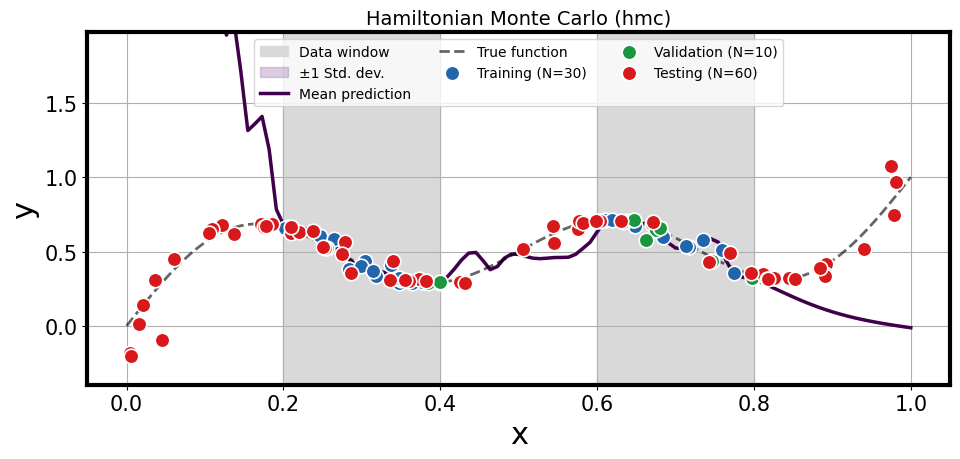

Saved: fit_hmc.png


In [87]:
show_fit(uqnet_hmc, 'Hamiltonian Monte Carlo (hmc)', slug='hmc')

---
## Method 3 — Variational Inference (`vi`)

**Idea:** approximate the posterior $p(\theta \mid \mathcal{D})$ with a
factorized Gaussian $q(\theta)$ by minimising the KL divergence
(Bayes-by-Backprop / ELBO).  Each weight has a learnable mean and variance.

**Key hyper-parameters:**
- `nepochs` — gradient descent iterations.
- `nsam` — number of weight samples drawn per ELBO estimate.
- `datanoise` — likelihood noise.

In [88]:
nnet = make_nnet()
uqnet_vi = NN_VI(nnet, verbose=True)

# VI converges slowly here: it optimizes a mean and a variance per weight, and
# the ELBO is a noisy objective. Fewer epochs leave the mean prediction flat.
uqnet_vi.fit(
    xtrn, ytrn,
    val=[xval, yval],
    datanoise=datanoise,
    lrate=0.1,
    batch_size=None,
    nsam=1,
    nepochs=20000,
)

=========== Deterministic model parameters ================
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
=========== Variational model parameters ==================
weight_pre_mu, shape (3, 1)
weight_pre_rho, shape (3, 1)
bias_pre_mu, shape (3,)
bias_pre_rho, shape (3,)
weight_post_mu, shape (1, 3)
weight_post_rho, shape (1, 3)
bias_post_mu, shape (1,)
bias_post_rho, shape (1,)
ww_0_mu, shape (3, 3)
ww_0_rho, shape (3, 3)
bb_0_mu, shape (3,)
bb_0_rho, shape (3,)
   NEpochs   NUpdates    BatchLoss      TrnLoss      ValLoss   BestLoss (Epoch)    LrnRate
         1         1  15709.720358 16434.712584  5791.788315   5791.788315 (0)       0.1
       100       100    836.914766   832.805243   346.213779    346.213779 (99)       0.1
       200       200    825.726611   823.886007   331.989257    331.989257 (199)       0.1
       300       300    818.219410   814.475078   333.509410    328.061824 (297)       

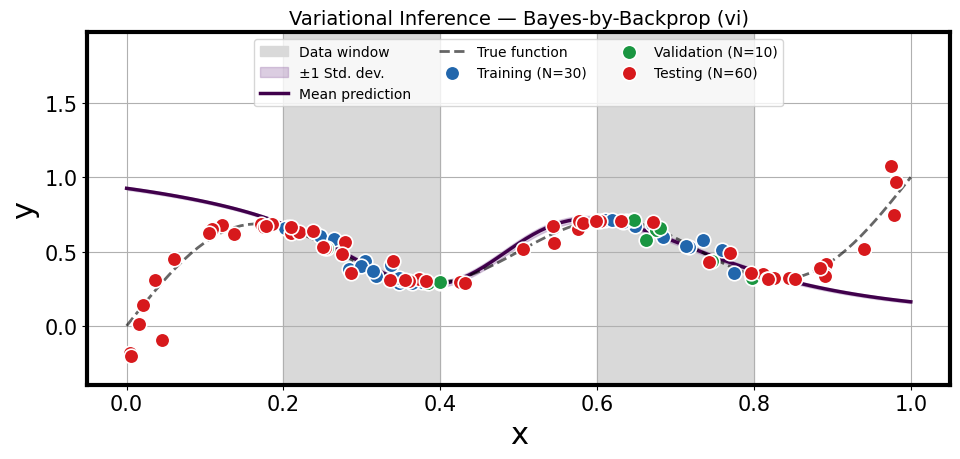

Saved: fit_vi.png


In [89]:
show_fit(uqnet_vi, 'Variational Inference \u2014 Bayes-by-Backprop (vi)', slug='vi')

---
## Method 4 — Deep Ensemble (`ens`)

**Idea:** train `nens` independent networks, each on a random subset of the
data, and treat their predictions as a mini-ensemble.  Cheap and
parallelizable.

**Key hyper-parameters:**
- `nens` — ensemble size (more members → richer uncertainty).
- `dfrac` — fraction of training data each member sees.
- `batch_size`, `lrate`, `nepochs` — standard SGD settings.

In [90]:
nnet = make_nnet()
uqnet_ens = NN_Ens(nnet, nens=5, dfrac=0.8, verbose=True)

# Each member is trained on its own random 80% of the training set (dfrac),
# which is where the spread between members comes from.
uqnet_ens.fit(
    xtrn, ytrn,
    val=[xval, yval],
    lrate=0.1,
    batch_size=None,
    nepochs=2000,
)

==========  Learner 1/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 2/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 3/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 4/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 5/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
======== Fitting Learner 1/5 =======
   NEpochs   NUpdates    BatchLoss      TrnLoss      ValLoss   BestLoss (Epoch)    LrnRate
         1         1      0.1861

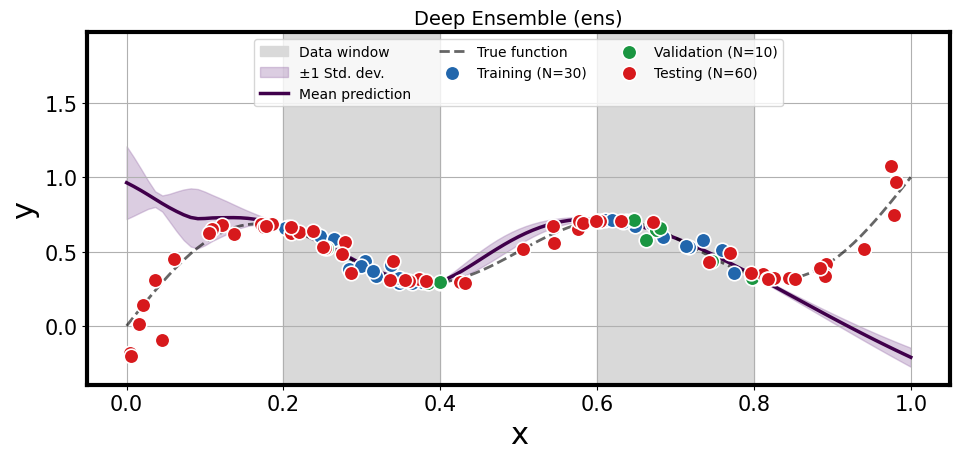

Saved: fit_ens.png


In [91]:
show_fit(uqnet_ens, 'Deep Ensemble (ens)', slug='ens')

---
## Method 5 — Randomized MAP Sampling (`rms`)

**Idea:** perturb the data and/or the prior and solve a MAP optimization
for each perturbation.  The resulting MAP solutions are approximate
posterior samples.  Combines point optimization with ensemble diversity.

**Key hyper-parameters (beyond ensemble settings):**
- `datanoise` — observation noise level used in the regularized loss.
- `priorsigma` — width of the Gaussian weight prior.

In [92]:
nnet = make_nnet()
uqnet_rms = NN_RMS(
    nnet, nens=7, dfrac=1.0, verbose=True,
    datanoise=datanoise, priorsigma=1.0,
)

uqnet_rms.fit(
    xtrn, ytrn,
    val=[xval, yval],
    lrate=0.1,
    batch_size=None,
    nepochs=2000,
)

==========  Learner 1/7  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 2/7  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 3/7  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 4/7  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 5/7  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 6/7  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, sha

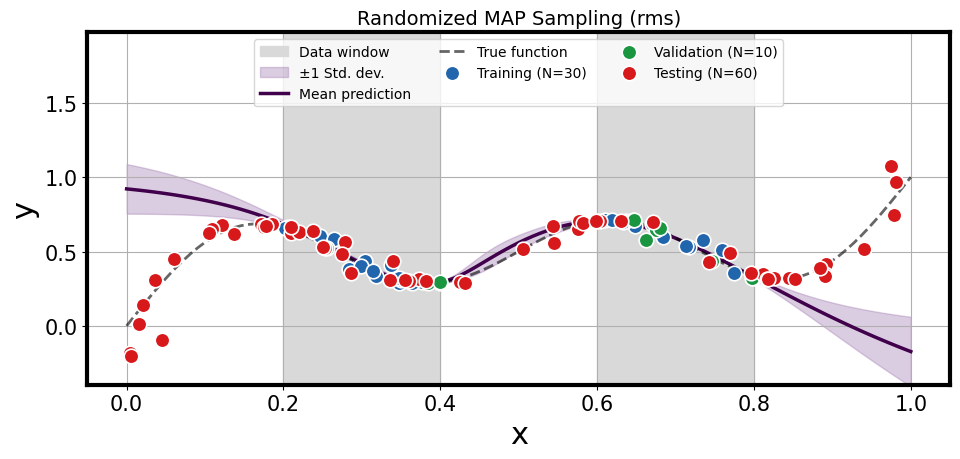

Saved: fit_rms.png


In [93]:
show_fit(uqnet_rms, 'Randomized MAP Sampling (rms)', slug='rms')

---
## Method 6 — Laplace Approximation (`laplace`)

**Idea:** fit a MAP solution, then fit a Gaussian to the posterior by
computing the Hessian of the negative log-posterior at the MAP point.
Samples from this Gaussian form the ensemble.

**Key hyper-parameters:**
- `la_type` — `'full'` for the full Hessian; `'diag'` for a cheaper
  diagonal version.

In [94]:
nnet = make_nnet()
# nens=1: a single MAP centre. Unlike NN_Ens, the Laplace posterior is a
# Gaussian fitted at that centre, so predict_ens() keeps drawing as many
# samples as asked for regardless of nens.
#
# cov_scale damps that Gaussian. As the constructor itself warns, the Hessian
# here is not averaged over the training points, so at cov_scale=1 its inverse
# is enormous and the sampled predictions blow up. This is the "hessian scale"
# hyperparameter that calibration refers to.
uqnet_laplace = NN_Laplace(
    nnet, nens=1, dfrac=1.0, verbose=True,
    la_type='full', cov_scale=1000.0,
    datanoise=datanoise, priorsigma=1.0,
)

uqnet_laplace.fit(
    xtrn, ytrn,
    val=[xval, yval],
    lrate=0.1,
    batch_size=None,
    nepochs=2000,
)

==========  Learner 1/1  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
NOTE: the hessian has not been averaged,  i.e., it has not been divided by the number of training data points. Hence, the hyperparameter hessian scale can be tuned to calibrate uncertainty.
======== Fitting Learner 1/1 =======
   NEpochs   NUpdates    BatchLoss      TrnLoss      ValLoss   BestLoss (Epoch)    LrnRate
         1         1   6333.572447  6333.572447  2437.061644   2437.061644 (0)       0.1
       100       100    786.488438   786.488438   278.228797    277.784528 (80)       0.1
       200       200    782.326596   782.326596   278.520901    277.784528 (80)       0.1
       300       300    771.941608   771.941608   277.660437    277.660437 (299)       0.1
       400       400    158.673948   158.673948   110.672703    110.672703 (399)       0.1
       500       500    163.297647   163.297647   103.571503   

/Users/ksargsy/Dropbox/Work/repos/quinn/quinn/solvers/nn_laplace.py:135: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  theta = np.random.multivariate_normal(self.means[jens], cov=self.cov_mats[jens])


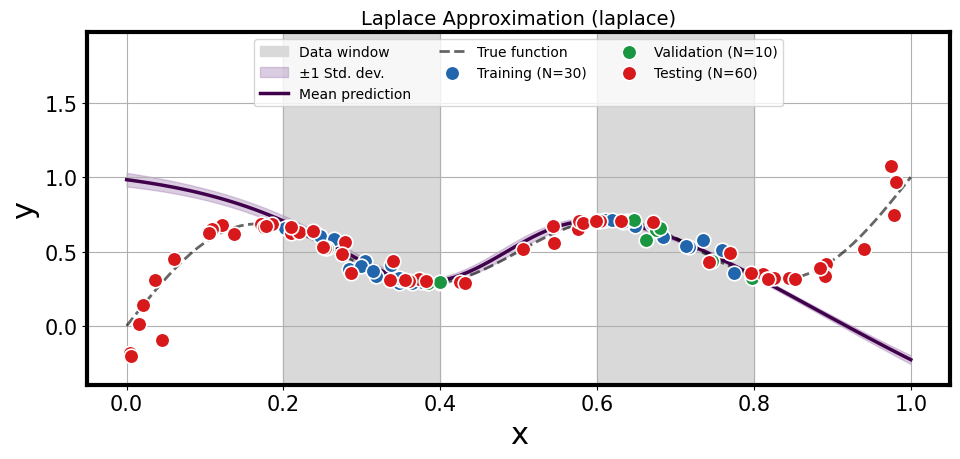

Saved: fit_laplace.png


In [95]:
show_fit(uqnet_laplace, 'Laplace Approximation (laplace)', slug='laplace')

---
## Method 7 — SWAG (`swag`)

**Idea:** run SGD with a cyclically varying learning rate and collect weight
snapshots.  Fit a Gaussian (low-rank + diagonal covariance) to the
trajectory; samples from this Gaussian are the posterior approximation.

**Key hyper-parameters:**
- `k` — columns in the low-rank deviation matrix.
- `n_steps` — number of SWAG weight collection steps.
- `c` — snapshot collection frequency (every `c` epochs).
- `cov_type` — `'lowrank'` or `'diag'`.
- `lr_swag` — learning rate during the SWAG collection phase.

In [96]:
nnet = make_nnet()
uqnet_swag = NN_SWAG(
    nnet, nens=5, dfrac=1.0, verbose=True,
    k=10, n_steps=20, c=1,
    cov_type='lowrank', lr_swag=0.01,
    datanoise=datanoise,
)

uqnet_swag.fit(
    xtrn, ytrn,
    val=[xval, yval],
    lrate=0.1,
    batch_size=None,
    nepochs=2000,
)

==========  Learner 1/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 2/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 3/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 4/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 5/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
======== Fitting Learner 1/5 =======
   NEpochs   NUpdates    BatchLoss      TrnLoss      ValLoss   BestLoss (Epoch)    LrnRate
         1         1   6303.0058

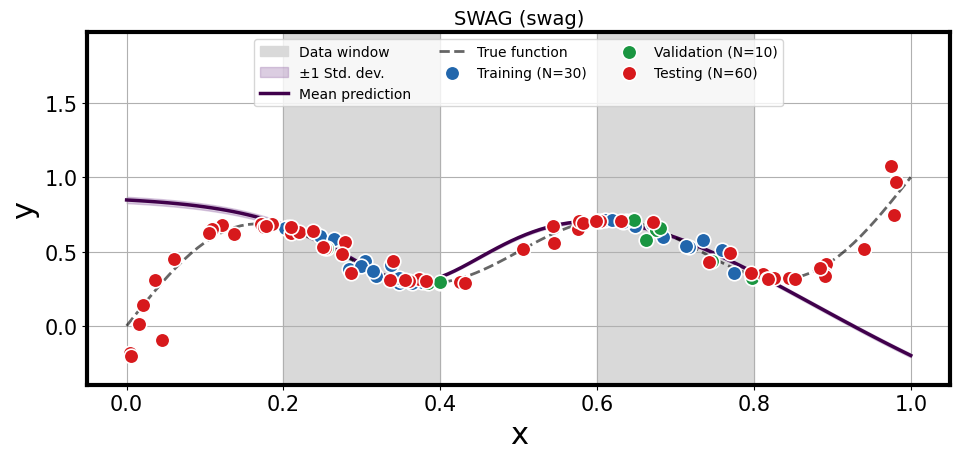

Saved: fit_swag.png


In [97]:
show_fit(uqnet_swag, 'SWAG (swag)', slug='swag')

---
## 4. Additional prediction API

All solvers share the same `QUiNNBase` API.  The cells below demonstrate
each method, with every figure also saved to `figures/`.

### 4.1 `predict_ens` — raw ensemble of predictions

Returns an array of shape `(M, N, o)` — `M` independent samples, each
evaluated at the `N` input points.  Here we draw 30 Laplace posterior
samples and overlay them on the grid.

Ensemble shape (M, N, o): (30, 111, 1)


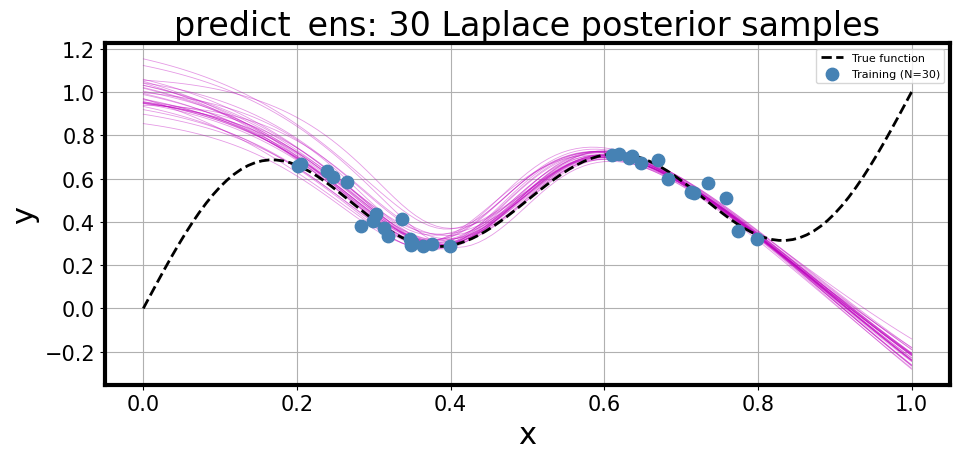

Saved: predict_ens_laplace.png


In [98]:
y_ens = uqnet_laplace.predict_ens(xgrid, nens=30)
print('Ensemble shape (M, N, o):', y_ens.shape)

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(y_ens.shape[0]):
    ax.plot(xgrid[:, 0], y_ens[i, :, 0], 'm-', lw=0.6, alpha=0.4)
ax.plot(xgrid[:, 0], ytrue[:, 0], 'k--', lw=2, label='True function')
ax.scatter(xtrn[:, 0], ytrn[:, 0], c='steelblue', s=80, zorder=10,
           label=f'Training (N={len(xtrn)})')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('predict_ens: 30 Laplace posterior samples')
ax.legend(fontsize=8, framealpha=0.8)
plt.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'predict_ens_laplace.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: predict_ens_laplace.png')

### 4.2 `predict_mom_sample` — mean, variance and covariance

| `msc` | Returns |
|-------|---------|
| `0`   | mean only (`yvar=None`, `ycov=None`) |
| `1`   | mean + variance |
| `2`   | mean + variance + full covariance matrix |

The right panel below shows the predictive covariance of the Deep
Ensemble as a heat-map.

Mean shape:        (111, 1)
Variance shape:    (111, 1)
Covariance shape:  (111, 111, 1)


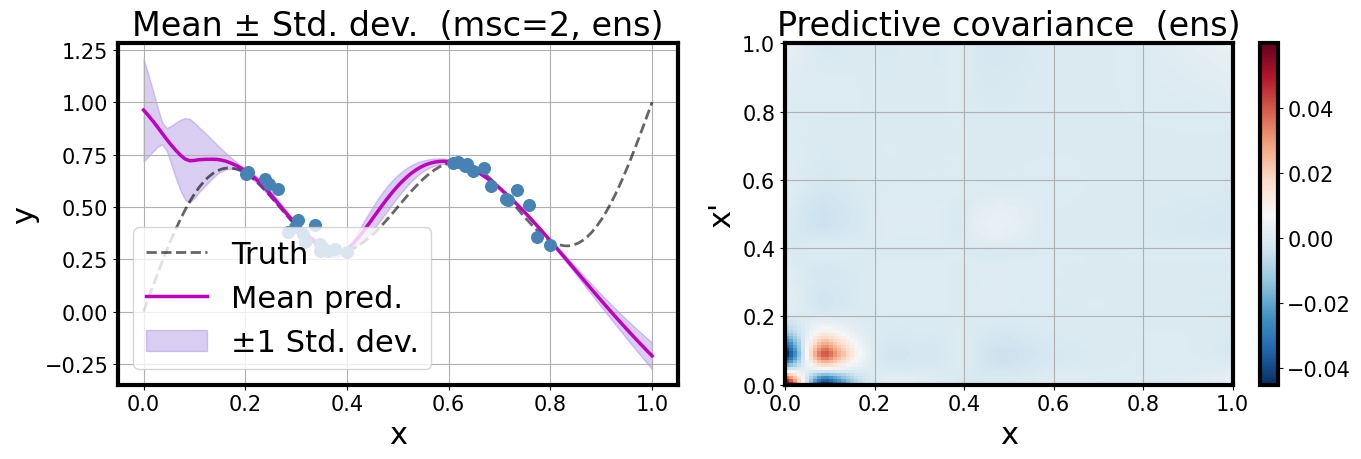

Saved: predict_mom_sample_ens.png


In [99]:
ymean, yvar, ycov = uqnet_ens.predict_mom_sample(xgrid, msc=2, nsam=300)
print('Mean shape:       ', ymean.shape)   # (N, o)
print('Variance shape:   ', yvar.shape)    # (N, o)
print('Covariance shape: ', ycov.shape)    # (N, N, o)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: mean ± std
ystd = np.sqrt(yvar[:, 0])
axes[0].plot(xgrid[:, 0], ytrue[:, 0], 'k--', lw=2, alpha=0.6, label='Truth')
axes[0].plot(xgrid[:, 0], ymean[:, 0], 'm-', lw=2.5, label='Mean pred.')
axes[0].fill_between(
    xgrid[:, 0], ymean[:, 0] - ystd, ymean[:, 0] + ystd,
    color='mediumpurple', alpha=0.35, label='±1 Std. dev.',
)
axes[0].scatter(xtrn[:, 0], ytrn[:, 0], c='steelblue', s=70, zorder=5)
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
axes[0].set_title('Mean ± Std. dev.  (msc=2, ens)')
axes[0].legend()

# right: covariance heat-map
im = axes[1].imshow(
    ycov[:, :, 0], origin='lower', aspect='auto', cmap='RdBu_r',
    extent=[xgrid[0, 0], xgrid[-1, 0], xgrid[0, 0], xgrid[-1, 0]],
)
plt.colorbar(im, ax=axes[1])
axes[1].set_title('Predictive covariance  (ens)')
axes[1].set_xlabel('x'); axes[1].set_ylabel("x'")

plt.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'predict_mom_sample_ens.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: predict_mom_sample_ens.png')

### 4.3 `predict` — posterior mean (convenience wrapper)

`predict(x)` is a shortcut for `predict_mom_sample(x, msc=0)[0]` and
returns only the posterior mean array of shape `(N, o)`.

In [100]:
ymean_only = uqnet_vi.predict(xgrid)   # shape (N, o)
print('predict output shape:', ymean_only.shape)

predict output shape: (111, 1)


### 4.4 `print_params` — inspect weight names and values

In [101]:
print('--- weight names only ---')
uqnet_ens.print_params(names_only=True)

print('\n--- weight names and values ---')
uqnet_ens.print_params(names_only=False)

--- weight names only ---
==========  Learner 1/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 2/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 3/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 4/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)
==========  Learner 5/5  ============
weight_pre, shape (3, 1)
bias_pre, shape (3,)
weight_post, shape (1, 3)
bias_post, shape (1,)
ww_0, shape (3, 3)
bb_0, shape (3,)

--- weight names and values ---
==========  Learner 1/5  ============
weight_pre tensor([[-6.3583],
        [-1.5116],
        [ 1.60

---
## 5. Side-by-side comparison

Three views of the same seven fits:

- **5.1** the posterior means overlaid, comparing the point predictions;
- **5.2** the uncertainty calibration curves, comparing the *uncertainties*;
- **5.3** a table of RMSE, calibration AUC and CRPS.

### 5.1 Posterior mean comparison

Saved to `figures/comparison_all_methods.png`.

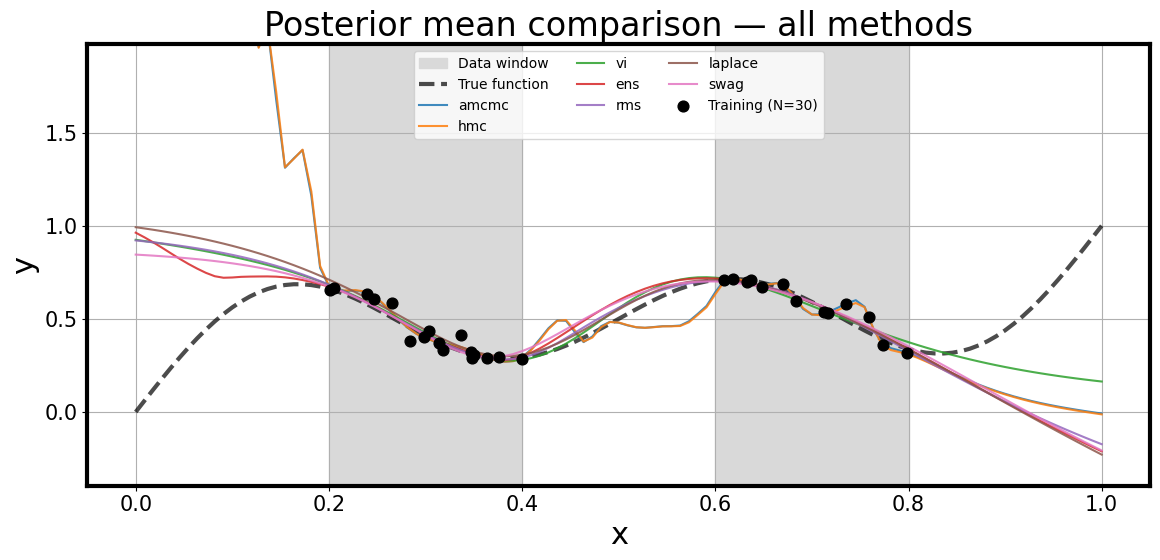

Saved: comparison_all_methods.png


In [102]:
solvers = {
    'amcmc':   uqnet_amcmc,
    'hmc':     uqnet_hmc,
    'vi':      uqnet_vi,
    'ens':     uqnet_ens,
    'rms':     uqnet_rms,
    'laplace': uqnet_laplace,
    'swag':    uqnet_swag,
}

fig, ax = plt.subplots(figsize=(12, 6))
shade_windows(ax)
ax.plot(xgrid[:, 0], ytrue[:, 0], 'k--', lw=3, alpha=0.7, label='True function')

for name, solver in solvers.items():
    ymean_s = solver.predict(xgrid)   # (N, 1)
    ax.plot(xgrid[:, 0], ymean_s[:, 0], lw=1.5, label=name, alpha=0.85)

ax.scatter(xtrn[:, 0], ytrn[:, 0], c='k', s=60, zorder=10,
           label=f'Training (N={len(xtrn)})')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_ylim(*YLIM)
ax.set_title('Posterior mean comparison — all methods')
ax.legend(loc='upper center', ncol=3, fontsize=10, framealpha=0.8)
plt.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'comparison_all_methods.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: comparison_all_methods.png')

### 5.2 Uncertainty calibration curves

Each curve asks: of the observations, what fraction actually falls below the
$q$-th percentile of its own predictive distribution?  For a well calibrated
method that fraction *is* $q$, putting the curve on the diagonal.

- **Below the diagonal** → over-confident: the bands are too narrow and the
  data fall outside them more often than promised.
- **Above the diagonal** → under-confident: the bands are wider than they
  need to be.

The area between a curve and the diagonal is the `AUC` reported in the
legend and in the table below.

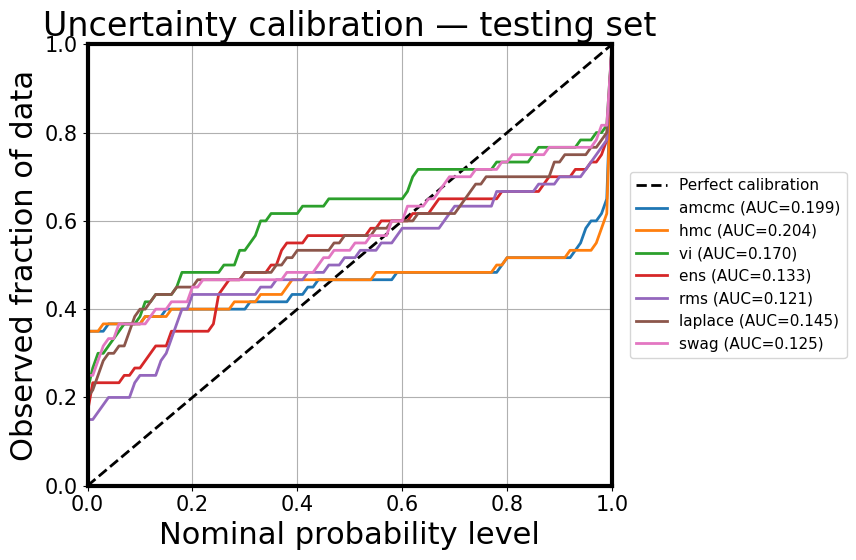

Saved: calibration_all_methods.png


In [103]:
# Predictive samples for every method on every split, computed once here and
# reused by both the calibration curves and the metrics table.
pred = {
    name: {'trn': predictive_samples(solver, xtrn),
           'val': predictive_samples(solver, xval),
           'tst': predictive_samples(solver, xtst)}
    for name, solver in solvers.items()
}

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot([0.0, 1.0], [0.0, 1.0], 'k--', lw=2, label='Perfect calibration')

for name in solvers:
    levels, observed = uc_curve(pred[name]['tst'], ytst)
    ax.plot(levels, observed, lw=2,
            label=f'{name} (AUC={calibration_auc(levels, observed):.3f})')

ax.set_xlabel('Nominal probability level')
ax.set_ylabel('Observed fraction of data')
ax.set_xlim(0.0, 1.0); ax.set_ylim(0.0, 1.0)
ax.set_title('Uncertainty calibration — testing set')
# Legend outside the axes, so it never covers a curve
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=11,
          framealpha=0.8)
plt.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'calibration_all_methods.png'), dpi=150,
            bbox_inches='tight')
plt.show()
print('Saved: calibration_all_methods.png')

### 5.3 Metrics table

`RMSE` on each split scores the mean fit, `AUC` scores the size of the
uncertainty and `CRPS` scores the two together.  The training and validation
RMSE are measured inside the data windows; everything labelled `tst` is over
the whole domain and therefore includes the extrapolation gaps.

In [104]:
rows = []
for name in solvers:
    levels, observed = uc_curve(pred[name]['tst'], ytst)
    rows.append({
        'method':   name,
        'RMSE trn': rmse(pred[name]['trn'], ytrn),
        'RMSE val': rmse(pred[name]['val'], yval),
        'RMSE tst': rmse(pred[name]['tst'], ytst),
        'AUC tst':  calibration_auc(levels, observed),
        'CRPS tst': crps(pred[name]['tst'], ytst),
    })

metrics = pd.DataFrame(rows).set_index('method')

print('Mean fit (RMSE), uncertainty (AUC) and full prediction (CRPS).')
print('Lower is better throughout. RMSE trn/val are inside the data windows,')
print('everything on the testing set spans the extrapolation gaps too.\n')
metrics.round(4)

Mean fit (RMSE), uncertainty (AUC) and full prediction (CRPS).
Lower is better throughout. RMSE trn/val are inside the data windows,
everything on the testing set spans the extrapolation gaps too.



,RMSE trn,RMSE val,RMSE tst,AUC tst,CRPS tst
method,,,,,
amcmc,0.0242,0.0684,1.0007,0.1992,0.5466
hmc,0.0246,0.0647,1.0002,0.2037,0.5497
vi,0.0403,0.0410,0.3540,0.1695,0.1754
ens,0.0366,0.0353,0.4046,0.1335,0.1971
rms,0.0374,0.0340,0.3988,0.1206,0.1918
laplace,0.0399,0.0380,0.4253,0.1450,0.2211
swag,0.0385,0.0400,0.3977,0.1245,0.2056


### Saved figures summary

In [105]:
saved = sorted(os.listdir(FIGDIR))
print(f'Files in {FIGDIR}/ ({len(saved)} total):')
for f in saved:
    path = os.path.join(FIGDIR, f)
    size_kb = os.path.getsize(path) / 1024
    print(f'  {f:<40}  {size_kb:6.1f} kB')

Files in figures/ (12 total):
  calibration_all_methods.png                132.3 kB
  comparison_all_methods.png                 141.0 kB
  data_overview.png                           69.3 kB
  fit_amcmc.png                               89.7 kB
  fit_ens.png                                 96.6 kB
  fit_hmc.png                                 85.3 kB
  fit_laplace.png                             96.7 kB
  fit_rms.png                                 96.2 kB
  fit_swag.png                                85.6 kB
  fit_vi.png                                  88.0 kB
  predict_ens_laplace.png                    159.5 kB
  predict_mom_sample_ens.png                 125.7 kB


---
## Summary

| Method   | Class        | Style           | Saved figure |
|----------|--------------|-----------------|----------------------------|
| `amcmc`  | `NN_MCMC`    | Sampling        | `fit_amcmc.png` |
| `hmc`    | `NN_MCMC`    | Sampling        | `fit_hmc.png` |
| `vi`     | `NN_VI`      | Variational     | `fit_vi.png` |
| `ens`    | `NN_Ens`     | Ensemble        | `fit_ens.png` |
| `rms`    | `NN_RMS`     | Ensemble/Optim. | `fit_rms.png` |
| `laplace`| `NN_Laplace` | Laplace approx. | `fit_laplace.png` |
| `swag`   | `NN_SWAG`    | Ensemble/Optim. | `fit_swag.png` |

Additional figures: `data_overview.png`, `predict_ens_laplace.png`,
`predict_mom_sample_ens.png`, `comparison_all_methods.png`,
`calibration_all_methods.png`.

All methods share the same inference API (`predict`, `predict_ens`,
`predict_mom_sample`) so they can be swapped without changing downstream
code.

**Reading the scores.**  Because the training data is confined to two windows,
the interesting question is not how well a method fits — they all do, inside
the windows — but what it claims about the gaps.  That is where the three
metrics separate: a small training RMSE together with a large calibration AUC
means a method that fits nicely and is then confidently wrong where it has no
data.  CRPS is the single number that penalises both halves of that.

For production runs, increase `nmcmc` (MCMC methods) or `nepochs`
(gradient-based methods) beyond the tutorial values used above.